# Módulo 04 — Demo: clasificación y segmentación de peces

Ahora vamos a juntar los dos modelos entrenados en una sola demostración. Dada una imagen, el sistema entrega la **especie** del pez con su **confianza** y la **máscara** de segmentación dibujada sobre la imagen.

El flujo es: imagen → **CNN** (módulo 02) → clase y confianza; imagen → **U-Net** (módulo 03) → máscara. Cada modelo tiene su propio preprocesamiento.

In [1]:
import json                          # lee el umbral del U-Net
import numpy as np                   # arreglos
import cv2                           # lectura, redimensionado y dibujo
from pathlib import Path             # rutas
from tensorflow import keras         # carga de modelos
import gradio as gr                  # interfaz web
from google.colab import drive       # acceso a Drive

In [2]:
!pip install -q gradio   # interfaz web de la demo

In [3]:
import gradio as gr

## 2. Rutas y carga de modelos
Ahora vamos a montar Drive y a cargar la CNN y el U-Net, y el umbral τ que guardamos en el módulo de la U-net.

In [4]:
drive.mount("/content/drive")                                  # monta Drive

ROOT = Path("/content/drive/MyDrive/sylfish")                  # raíz del proyecto
MODELS_DIR = ROOT / "models"                                   # modelos entrenados

CLASES = ["boal", "ilish", "kalibaush", "katla", "koi",
          "mrigel", "pabda", "rui", "telapia"]                 # mismo orden que el módulo 02

cnn = keras.models.load_model(MODELS_DIR / "cnn_best.keras")                    # CNN ganadora (tl_fase2)
unet = keras.models.load_model(MODELS_DIR / "unet_v1.keras", compile=False)     # sin compilar: solo inferencia
TAU = json.load(open(MODELS_DIR / "unet_v1_umbral.json"))                       # umbral de binarización

print(TAU)                                                     # ver la clave real del JSON
print(cnn.input_shape, unet.input_shape)                       # esperado: (None, 224, 224, 3) y (None, 256, 256, 3)
print(f"cnn_best.keras: {(MODELS_DIR / 'cnn_best.keras').stat().st_size / 1e6:.1f} MB")   # esperado ≈ 29 MB

Mounted at /content/drive
{'tau': 0.6, 'miou_val': 0.8334124466585993}
(None, 224, 224, 3) (None, 256, 256, 3)
cnn_best.keras: 29.1 MB


## 3. Preprocesamiento

Ahora vamos a definir una función por modelo. La CNN espera 224×224 en RGB con valores 0–255 (EfficientNetB0 normaliza por dentro), y el U-Net espera 256×256 en RGB dividido entre 255.

In [5]:
IMG_CNN = 224                       # tamaño de entrada de la CNN
IMG_UNET = 256                      # tamaño de entrada del U-Net

def preparar_cnn(img_rgb):
    x = cv2.resize(img_rgb, (IMG_CNN, IMG_CNN), interpolation=cv2.INTER_AREA)   # igual que el caché del módulo 01
    return x.astype("float32")[None, ...]                                       # 0–255 sin dividir; (1,224,224,3)

def preparar_unet(img_rgb):
    x = cv2.resize(img_rgb, (IMG_UNET, IMG_UNET), interpolation=cv2.INTER_AREA) # a 256×256
    return (x.astype("float32") / 255.0)[None, ...]                             # [0,1]; (1,256,256,3)

print([l.name for l in cnn.layers])      # debe aparecer 'efficientnetb0' y NO 'rescalado'

['entrada', 'aumento', 'efficientnetb0', 'gap_tl', 'dropout_tl', 'salida_tl']


## 4. Prueba con una imagen

Ahora vamos a subir una foto, pasarla por la CNN y por el U-Net, y revisar que las salidas tengan sentido: clase, confianza y área de la máscara.

In [6]:
from google.colab import files                                  # subida de archivos en Colab

subido = files.upload()                                         # elige una foto de un pez
nombre = list(subido.keys())[0]                                 # nombre del archivo subido
img_bgr = cv2.imdecode(np.frombuffer(subido[nombre], np.uint8), cv2.IMREAD_COLOR)   # OpenCV lee en BGR
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)              # a RGB, como los modelos esperan
print("imagen:", img_rgb.shape)

# --- CNN: clase y confianza ---
probs = cnn.predict(preparar_cnn(img_rgb), verbose=0)[0]        # vector de 9 probabilidades
k = int(np.argmax(probs))                                       # índice de la clase más probable
print(f"clase: {CLASES[k]} | confianza: {probs[k]*100:.1f}%")

# --- U-Net: máscara y área ---
prob_mask = unet.predict(preparar_unet(img_rgb), verbose=0)[0, ..., 0]    # (256,256) en [0,1]
mascara = (prob_mask > TAU["tau"]).astype("uint8")              # binariza con τ = 0.6
area = mascara.mean()                                           # fracción de la imagen que ocupa el pez
print(f"área de la máscara: {area*100:.1f}% de la imagen")

Saving images.jpg to images.jpg
imagen: (279, 520, 3)
clase: rui | confianza: 94.9%
área de la máscara: 21.9% de la imagen


## 5. Dibujo del resultado

Ahora vamos a definir la función que pinta el contorno del pez sobre la imagen y una leyenda con la especie y la confianza.

In [11]:
def dibujar_resultado(img_rgb, mascara, clase, conf, fiable=True):
    salida = img_rgb.copy()                                               # no modifica la original
    mascara = cv2.resize(mascara, (img_rgb.shape[1], img_rgb.shape[0]),
                         interpolation=cv2.INTER_NEAREST)                 # de 256×256 al tamaño original
    contornos, _ = cv2.findContours(mascara.astype(np.uint8),
                                    cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contornos) == 0:
        return salida                                                     # sin pez detectado: solo la imagen
    c = max(contornos, key=cv2.contourArea)                               # contorno más grande
    color = (0, 255, 0) if fiable else (255, 140, 0)                      # verde / naranja (RGB)
    grosor = max(2, salida.shape[1] // 200)                               # proporcional al ancho
    cv2.drawContours(salida, [c], -1, color, grosor)

    x, y, w, h = cv2.boundingRect(c)                                      # caja del pez, para ubicar la leyenda
    texto = f"{clase}  {conf*100:.1f}%"
    escala = max(0.6, salida.shape[1] / 900)
    (tw, th), base = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, 2)
    y0 = max(th + base + 4, y)                                            # si no cabe arriba, baja dentro de la imagen
    cv2.rectangle(salida, (x, y0 - th - base - 4), (x + tw + 8, y0), color, -1)   # fondo de la leyenda
    cv2.putText(salida, texto, (x + 4, y0 - base - 2),
                cv2.FONT_HERSHEY_SIMPLEX, escala, (0, 0, 0), 2)           # texto negro
    return salida

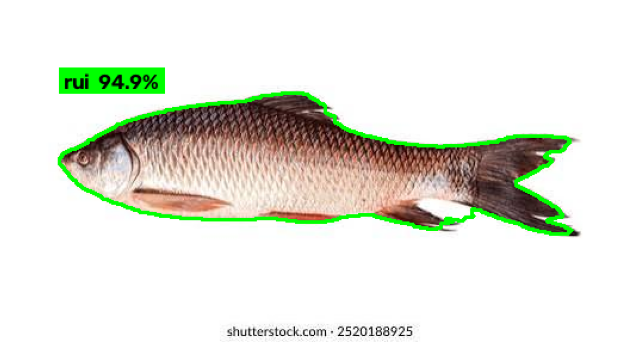

In [8]:
import matplotlib.pyplot as plt                                           # para mostrar en Colab

resultado = dibujar_resultado(img_rgb, mascara, CLASES[k], probs[k], fiable=(0.02 <= area <= 0.35))
plt.figure(figsize=(8, 5))
plt.imshow(resultado)
plt.axis("off")
plt.show()

Luego de la prueba generamos una función que realice todo lo anterior

Especie: rui (94.9%)
Área del pez: 21.9% de la imagen


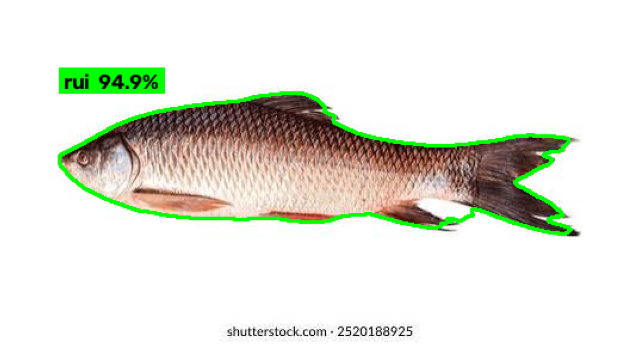

In [9]:
AREA_MIN, AREA_MAX = 0.02, 0.35        # rango de área fiable (el mismo del control de calidad del módulo 01)

def predecir(img_rgb):
    if img_rgb is None:
        return None, "Sube una imagen."                                       # Gradio puede enviar None

    # --- CNN: clase y confianza ---
    probs = cnn.predict(preparar_cnn(img_rgb), verbose=0)[0]
    k = int(np.argmax(probs))

    # --- U-Net: probabilidades ampliadas al tamaño original, luego τ ---
    prob_mask = unet.predict(preparar_unet(img_rgb), verbose=0)[0, ..., 0]    # (256,256)
    prob_mask = cv2.resize(prob_mask, (img_rgb.shape[1], img_rgb.shape[0]),
                           interpolation=cv2.INTER_LINEAR)                    # bilineal: borde más suave
    mascara = (prob_mask > TAU["tau"]).astype("uint8")
    area = mascara.mean()
    fiable = AREA_MIN <= area <= AREA_MAX                                     # ¿área plausible para un pez?

    salida = dibujar_resultado(img_rgb, mascara, CLASES[k], probs[k], fiable)

    texto = f"Especie: {CLASES[k]} ({probs[k]*100:.1f}%)\nÁrea del pez: {area*100:.1f}% de la imagen"
    if not fiable:
        texto += "\nAviso: segmentación poco fiable (área fuera de rango)."
    return salida, texto

salida, texto = predecir(img_rgb)                                             # probamos con la misma imagen
print(texto)
plt.figure(figsize=(8, 5)); plt.imshow(salida); plt.axis("off"); plt.show()

## 7. Interfaz con Gradio

Ahora vamos a envolver la función `predecir` en una interfaz web: el usuario sube una foto y recibe la imagen con el contorno y la leyenda, más un resumen en texto.

In [10]:
TITULO = "SylFish — Clasificación y segmentación de peces"        # título de la interfaz

DESCRIPCION = (
    "Sube una foto de un pez. El sistema identifica la especie (CNN con transfer learning) "
    "y dibuja su contorno (U-Net). Especies: boal, ilish, kalibaush, katla, koi, mrigel, pabda, rui, telapia.\n\n"
    "La confianza no es una probabilidad calibrada. Entrenado con fotos del dataset SylFish: "
    "con otros fondos o escenas puede fallar más."
)

PIE = "Proyecto final — Inteligencia Artificial 2026-2 · Universidad del Magdalena"

demo = gr.Interface(
    fn=predecir,                                                  # función del paso 6
    inputs=gr.Image(type="numpy", label="Foto del pez"),          # llega como arreglo RGB
    outputs=[
        gr.Image(label="Resultado"),                              # imagen con contorno y leyenda
        gr.Textbox(label="Resumen", lines=3),                     # texto de la función
    ],
    title=TITULO,
    description=DESCRIPCION,
    article=PIE,
    flagging_mode="never",                                        # sin botón Flag
)

demo.launch(share=True)                                           # enlace público temporal, ideal para presentar

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8ef49eab41267df3bc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
